## Image Preprocessing

In [1]:
import os
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image

import tensorflow as tf

In [2]:
DATASET_DIR = Path("../dataset")

TRAIN_DIR = DATASET_DIR / "Training"
TEST_DIR = DATASET_DIR / "Testing"

print("Training directory exists:", TRAIN_DIR.exists())
print("Testing directory exists:", TEST_DIR.exists())

Training directory exists: True
Testing directory exists: True


## 1 Image Resizing

Target image dimensions: 224 × 224 pixels.

In [3]:
# Target image dimensions
IMG_SIZE = (224, 224)
print("Target image size:", IMG_SIZE)

Target image size: (224, 224)


In [4]:
#select one mri image from training data 
image_extensions = {".jpg", ".jpeg", ".png"}

training_images = [path for path in TRAIN_DIR.rglob("*") if path.suffix.lower() in image_extensions]

sample_path = random.choice(training_images) 
original_img = Image.open(sample_path) 

print("Image path:", sample_path)
print("Original dimensions:", original_img.size)
print("Original image mode:", original_img.mode)

Image path: ..\dataset\Training\meningioma\Tr-me_696.jpg
Original dimensions: (512, 512)
Original image mode: L


In [5]:
# Resize MRI image
resized_img = original_img.resize(IMG_SIZE,Image.Resampling.LANCZOS)

print("Original dimensions:", original_img.size)
print("Resized dimensions:", resized_img.size)

Original dimensions: (512, 512)
Resized dimensions: (224, 224)


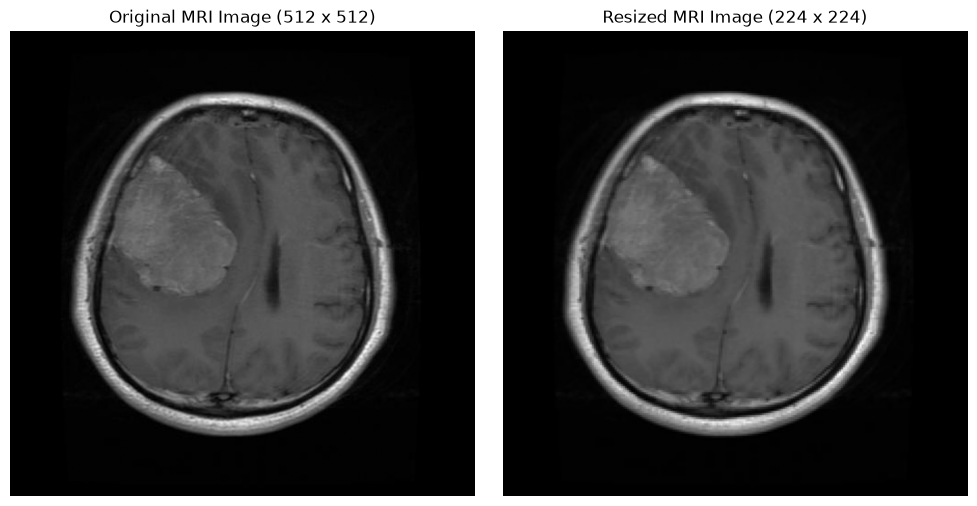

In [6]:
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(original_img, cmap="gray")
plt.title("Original MRI Image (512 x 512)")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(resized_img, cmap="gray")
plt.title("Resized MRI Image (224 x 224)")
plt.axis("off")

plt.tight_layout()
plt.show() 

In [7]:
print("Original size:", original_img.size)
print("Resized size:", resized_img.size)

print("Original image type:", type(original_img)) 
print("Resized image type:", type(resized_img)) 

Original size: (512, 512)
Resized size: (224, 224)
Original image type: <class 'PIL.JpegImagePlugin.JpegImageFile'>
Resized image type: <class 'PIL.Image.Image'>


## 2  Image Normalization

In [8]:
# Convert resized image into NumPy array
image_array = np.array(resized_img)

print("Array shape:", image_array.shape)
print("Data type:", image_array.dtype)
print("Minimum pixel value:", image_array.min())
print("Maximum pixel value:", image_array.max())

Array shape: (224, 224)
Data type: uint8
Minimum pixel value: 0
Maximum pixel value: 246


In [9]:
# Normalize pixel values from 0-255 to 0-1
normalized_img = image_array.astype("float32") / 255.0

print("Normalized data type:", normalized_img.dtype)
print("Minimum normalized value:", normalized_img.min())
print("Maximum normalized value:", normalized_img.max())

Normalized data type: float32
Minimum normalized value: 0.0
Maximum normalized value: 0.9647059


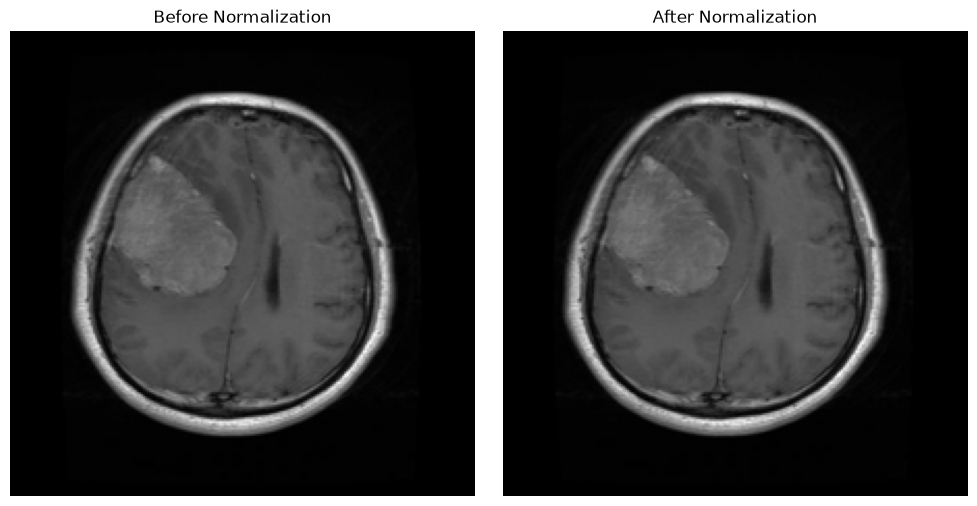

In [10]:
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(resized_img, cmap="gray")
plt.title("Before Normalization")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(normalized_img, cmap="gray")
plt.title("After Normalization")
plt.axis("off")

plt.tight_layout()
plt.show()

In [11]:
# Get class names from training folders
class_names = sorted([folder.name for folder in TRAIN_DIR.iterdir() if folder.is_dir()])

print("Class names:", class_names)
print("Total classes:", len(class_names))

Class names: ['glioma', 'meningioma', 'notumor', 'pituitary']
Total classes: 4


In [12]:
# Convert class names into numerical labels
class_to_label = {class_name: index for index, class_name in enumerate(class_names)}
print("Class to label mapping:")

for class_name, label in class_to_label.items():
    print(f"{class_name} - {label}")

Class to label mapping:
glioma - 0
meningioma - 1
notumor - 2
pituitary - 3


In [13]:
# Get the class name from the image's parent folder
sample_class = sample_path.parent.name
# Convert class name into numerical label
sample_label = class_to_label[sample_class]

print("Image:", sample_path.name)
print("Actual class:", sample_class) 
print("Encoded label:", sample_label)

Image: Tr-me_696.jpg
Actual class: meningioma
Encoded label: 1


In [14]:
# Collect image paths
image_extensions = {".jpg", ".jpeg", ".png"}

train_paths = sorted([path for path in TRAIN_DIR.rglob("*") if (path.suffix.lower() in image_extensions)])
test_paths = sorted([path for path in TEST_DIR.rglob("*") if (path.suffix.lower() in image_extensions)])

# Encode labels
train_labels = np.array([class_to_label[path.parent.name] for path in train_paths])
test_labels = np.array([class_to_label[path.parent.name] for path in test_paths])

print("Training labels shape:", train_labels.shape)
print("Testing labels shape:", test_labels.shape)

print("First 10 training labels:", train_labels[:10])

Training labels shape: (5600,)
Testing labels shape: (1600,)
First 10 training labels: [0 0 0 0 0 0 0 0 0 0]


In [15]:
# Count images belonging to each encoded class  
for class_name, label in class_to_label.items():
    train_count = np.sum(train_labels == label)
    test_count = np.sum(test_labels == label) 
    print(f"{class_name}: Training = {train_count} Testing = {test_count}")

glioma: Training = 1400 Testing = 400
meningioma: Training = 1400 Testing = 400
notumor: Training = 1400 Testing = 400
pituitary: Training = 1400 Testing = 400


## 4  Train, Validation and Test Splitting

In [16]:
from sklearn.model_selection import train_test_split

# Spliting existing training data into training and validation
X_train, X_val, y_train, y_val = train_test_split(train_paths,train_labels,test_size=0.2,random_state=42,stratify=train_labels)

# Keeping original testing data separate
X_test = test_paths 
y_test = test_labels

In [17]:
print("Training images:", len(X_train))
print("Validation images:", len(X_val))
print("Testing images:", len(X_test))
print("Total images:",len(X_train) + len(X_val) + len(X_test))

Training images: 4480
Validation images: 1120
Testing images: 1600
Total images: 7200


In [18]:
for class_name, label in class_to_label.items():
    train_count = np.sum(y_train == label)
    val_count = np.sum(y_val == label)
    test_count = np.sum(y_test == label)
    print(f"{class_name}: Train={train_count}, Validation={val_count}, Test={test_count}")

glioma: Train=1120, Validation=280, Test=400
meningioma: Train=1120, Validation=280, Test=400
notumor: Train=1120, Validation=280, Test=400
pituitary: Train=1120, Validation=280, Test=400


In [19]:
train_set = set(X_train)
val_set = set(X_val)
test_set = set(X_test)

print("Train vs Validation:", len(train_set & val_set))
print("Train vs Test:", len(train_set & test_set))
print("Validation vs Test:", len(val_set & test_set))

Train vs Validation: 0
Train vs Test: 0
Validation vs Test: 0


## 5 Data Augmentation

In [20]:
from tensorflow.keras import layers

# Select one training image
augmentation_sample_path = X_train[0]

# Load and resize image
sample_image = tf.keras.utils.load_img(augmentation_sample_path,target_size=IMG_SIZE,color_mode="grayscale")

# Convert image into NumPy array 
sample_array = tf.keras.utils.img_to_array(sample_image)

# Normalize pixel values
sample_array = sample_array / 255.0

# Add batch dimension
sample_batch = tf.expand_dims(sample_array, axis=0)

print("Image shape:", sample_array.shape)
print("Batch shape:", sample_batch.shape)
print("Minimum pixel:", sample_array.min())
print("Maximum pixel:", sample_array.max())

Image shape: (224, 224, 1)
Batch shape: (1, 224, 224, 1)
Minimum pixel: 0.0
Maximum pixel: 0.99607843


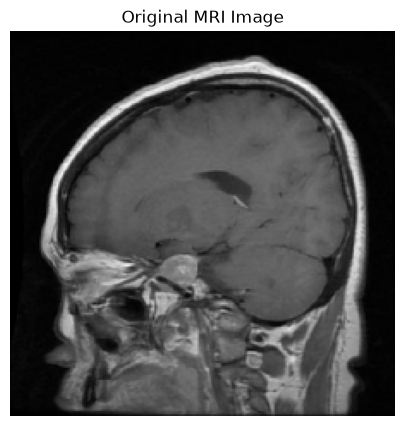

In [21]:
plt.figure(figsize=(5, 5))

plt.imshow(sample_array.squeeze(), cmap="gray")
plt.title("Original MRI Image")
plt.axis("off")
plt.show()

In [22]:
# Create rotation augmentation layer
rotation_layer = layers.RandomRotation(factor=0.05,fill_mode="nearest",seed=42)

#  Apply rotation to our sample MRI image
rotated_batch = rotation_layer(sample_batch,training=True)
rotated_image = rotated_batch[0].numpy()

print("Original shape:", sample_array.shape)
print("Rotated shape:", rotated_image.shape)

Original shape: (224, 224, 1)
Rotated shape: (224, 224, 1)


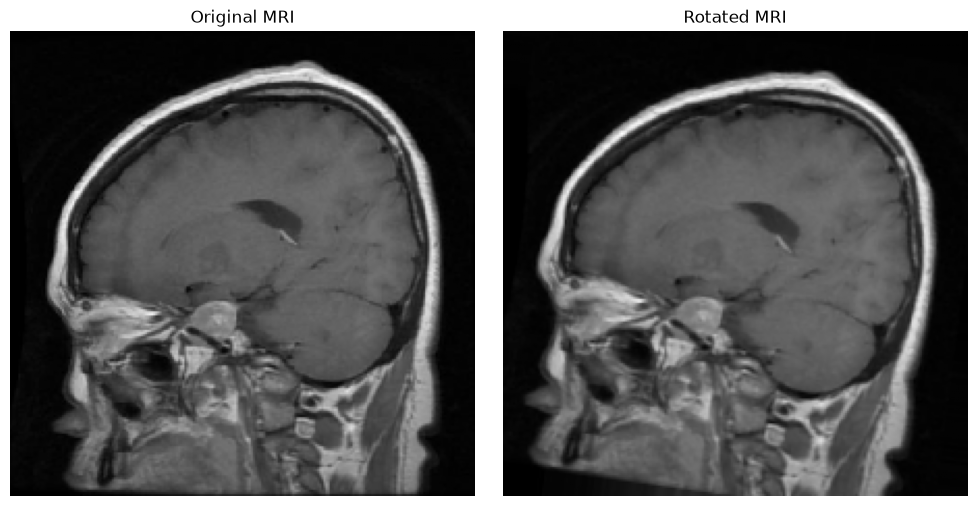

In [23]:
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(sample_array.squeeze(), cmap="gray")
plt.title("Original MRI")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(rotated_image.squeeze(), cmap="gray")
plt.title("Rotated MRI")
plt.axis("off")

plt.tight_layout()
plt.show()

In [24]:
#Translation layer is created 
translation_layer = layers.RandomTranslation(height_factor=0.05,width_factor=0.05,fill_mode='nearest',seed=42)

shifted_batch = translation_layer(sample_batch,training=True)
shifted_image = shifted_batch[0].numpy()

print("Original shape:", sample_array.shape)
print("Shifted shape:", shifted_image.shape)

Original shape: (224, 224, 1)
Shifted shape: (224, 224, 1)


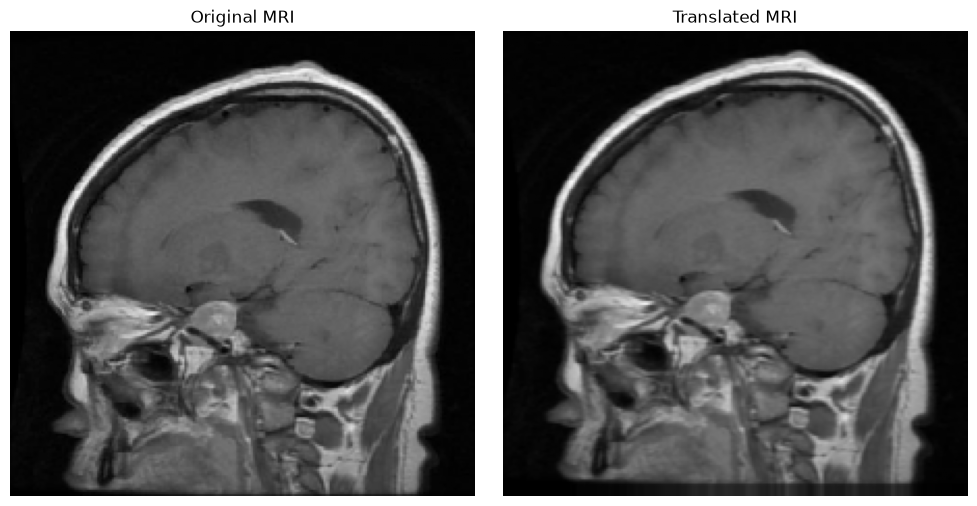

In [25]:
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(sample_array.squeeze(), cmap="gray")
plt.title("Original MRI")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(shifted_image.squeeze(), cmap="gray")
plt.title("Translated MRI")
plt.axis("off")

plt.tight_layout()
plt.show()

In [26]:
zoom_layer = layers.RandomZoom(height_factor=0.10,width_factor=0.10,fill_mode="nearest",seed=42)
zoomed_batch = zoom_layer(sample_batch,training=True)
zoomed_image = zoomed_batch[0].numpy()

print("Original shape:", sample_array.shape)
print("Zoomed shape:", zoomed_image.shape)

Original shape: (224, 224, 1)
Zoomed shape: (224, 224, 1)


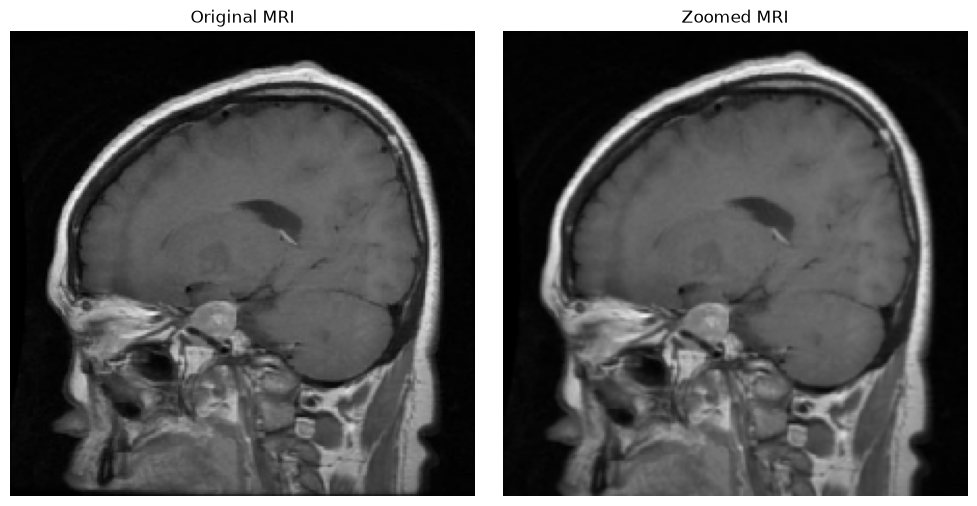

In [27]:
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(sample_array.squeeze(), cmap="gray")
plt.title("Original MRI")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(zoomed_image.squeeze(), cmap="gray")
plt.title("Zoomed MRI")
plt.axis("off")

plt.tight_layout()
plt.show()

In [28]:
flip_layer = layers.RandomFlip(mode="horizontal",seed=42)

flipped_batch = flip_layer(sample_batch,training=True)
flipped_image = flipped_batch[0].numpy()

print("Original shape:", sample_array.shape)
print("Flipped shape:", flipped_image.shape)

Original shape: (224, 224, 1)
Flipped shape: (224, 224, 1)


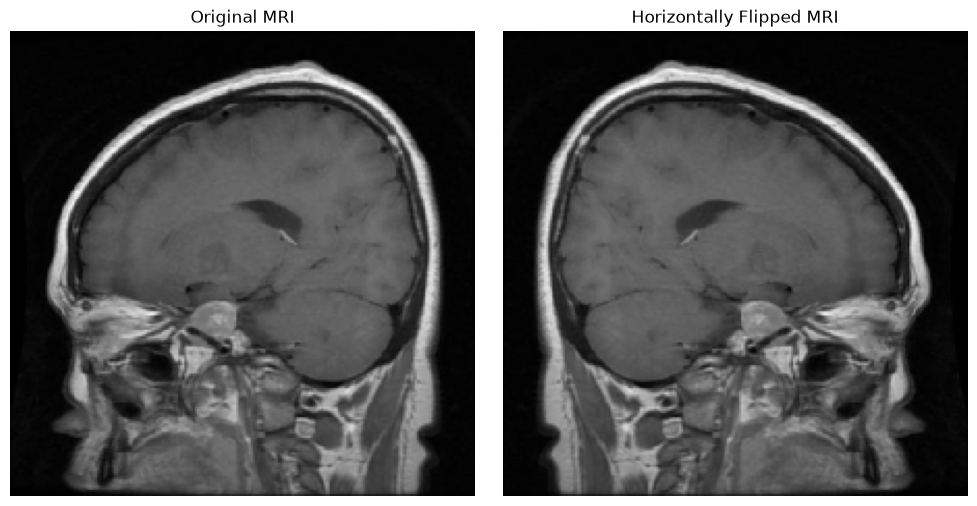

In [29]:
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(sample_array.squeeze(), cmap="gray")
plt.title("Original MRI")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(flipped_image.squeeze(), cmap="gray")
plt.title("Horizontally Flipped MRI")
plt.axis("off")

plt.tight_layout()
plt.show()

## Build our augmentation pipeline

In [30]:
data_augmentation = tf.keras.Sequential([layers.RandomRotation(factor=0.05,fill_mode="nearest"),
                                         layers.RandomTranslation(height_factor=0.05,width_factor=0.05,fill_mode="nearest"),
                                         layers.RandomZoom(height_factor=0.10,width_factor=0.10,fill_mode="nearest")])

augmented_batch = data_augmentation(sample_batch,training=True) 
augmented_image = augmented_batch[0].numpy() 

print("Original shape:", sample_array.shape) 
print("Augmented shape:", augmented_image.shape) 

Original shape: (224, 224, 1)
Augmented shape: (224, 224, 1)


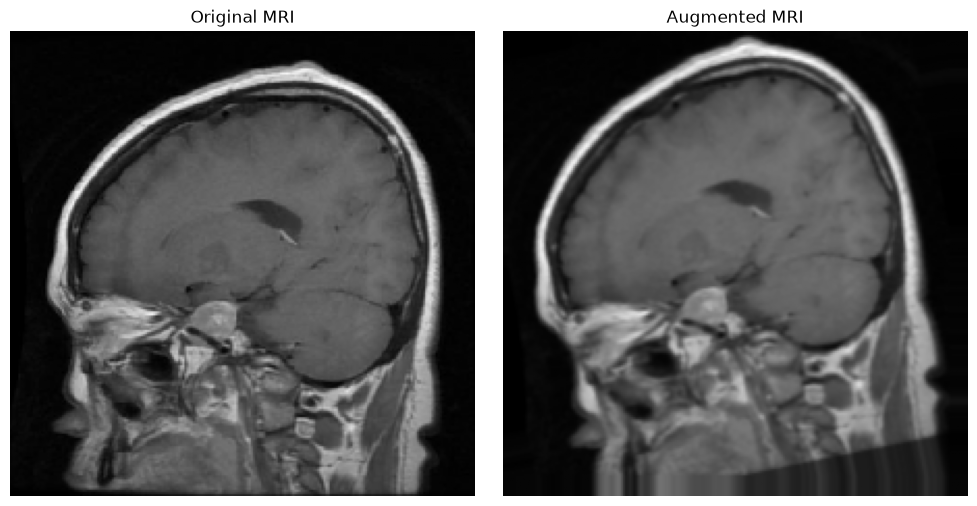

In [31]:
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(sample_array.squeeze(), cmap="gray")
plt.title("Original MRI")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(augmented_image.squeeze(), cmap="gray")
plt.title("Augmented MRI")
plt.axis("off")

plt.tight_layout()
plt.show()